In [8]:
import numpy as np
import math
import qiskit
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit
from qiskit_aer import AerSimulator # Virtual backend with noise simulation
from qiskit.primitives import BackendSamplerV2, BackendEstimatorV2 # Primitive building blocks
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager # Transpilation
from qiskit.visualization import plot_histogram
from qiskit.quantum_info import SparsePauliOp # Pauli strings

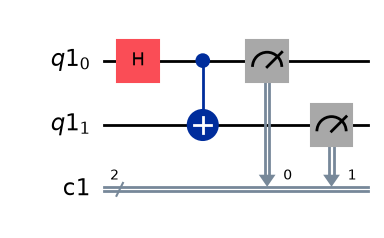

In [9]:
q = QuantumRegister(2)
c = ClassicalRegister(2)

qc = QuantumCircuit(q,c)

# Adding gates
qc.h(q[0]) # Hadamard
qc.cx(q[0],q[1]) # CNOT
qc.measure(q,c) 

qc.draw("mpl")


In [10]:
# Transpilation

backend = AerSimulator(method='statevector')
sampler = BackendSamplerV2(backend=backend)
estimator = BackendEstimatorV2(backend=backend)

target = backend.target
pm = generate_preset_pass_manager(target=target, optimization_level=3)

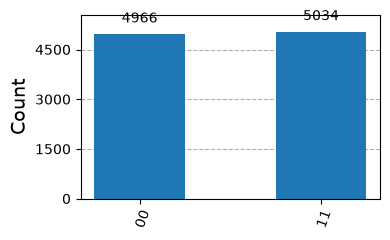

In [12]:
# Sample the output of the circuit

qc_isa = pm.run(qc) # Instruction set architecture

job = sampler.run([qc_isa], shots=10000)
result = job.result()[0]
counts = result.join_data().get_counts()

plot_histogram(counts, figsize=(4,2.5))

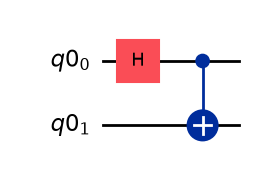

In [5]:
# Calculating expectation values

# Define circuit again
# We no not need measurement this time
qc = QuantumCircuit(q)
# Adding gates
qc.h(q[0]) # Hadamard
qc.cx(q[0],q[1]) # CNOT

qc.draw("mpl")

In [7]:
pauli_str = ['ZZ', 'IZ', 'XY']
obs = [SparsePauliOp(x) for x in pauli_str]

# Transpilation
qc_isa = pm.run(qc)
obs_isa = [x.apply_layout(layout=qc_isa.layout) for x in obs]

# Execute circuit
pub = [(qc_isa, obs_isa)]
job = estimator.run(pub)
res = job.result()
res = res[0].data.evs

for i in range(len(res)): 
    print(f"< {pauli_str[i]} > = {res[i]}")

< ZZ > = 1.0
< IZ > = -0.00146484375
< XY > = -0.03466796875
